# Covid-19 in Spring 2020: Curve Fitting and Time-Series Clustering of Countries

Written by hand between March and May 2020, while the first wave was unfolding.

Data: ECDC worldwide case data (snapshot 2020-04-09, see `data/`) and a 2020 population table.

## 1. Importing Packages, Loading Dataset, Adjustments

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import datetime
from datetime import date, timedelta
import warnings
warnings.filterwarnings('ignore')
from scipy.optimize import curve_fit
from scipy.optimize import fsolve
from sklearn.metrics import mean_squared_error
from tslearn.clustering import TimeSeriesKMeans
from sklearn.preprocessing import MinMaxScaler
from tslearn import metrics
from sklearn.manifold import MDS
from sklearn.cluster import KMeans

In [31]:
covid_dataset =\
pd.read_excel(r'C:\Users\Bernhard Brugger\Desktop\CoVid_19\COVID-19-geographic-disbtribution-worldwide-2020-04-09.xlsx')

In [32]:
covid_dataset.head()

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,geoId,countryterritoryCode,popData2018
0,2020-04-09,9,4,2020,56,3,Afghanistan,AF,AFG,37172386.0
1,2020-04-08,8,4,2020,30,4,Afghanistan,AF,AFG,37172386.0
2,2020-04-07,7,4,2020,38,0,Afghanistan,AF,AFG,37172386.0
3,2020-04-06,6,4,2020,29,2,Afghanistan,AF,AFG,37172386.0
4,2020-04-05,5,4,2020,35,1,Afghanistan,AF,AFG,37172386.0


In [33]:
covid_dataset = covid_dataset.rename(columns = {'countriesAndTerritories': 'Countries and territories', \
                                               'dateRep': 'DateRep', 'cases': 'Cases', 'deaths': 'Deaths'})

In [34]:
# Replace missing data in switzerland
index_value = covid_dataset[covid_dataset['Countries and territories'] == 'Switzerland']
index_value = index_value[index_value['DateRep'] == datetime.date(2020,3,17)].index[0]
covid_dataset.set_value(index_value, 'Cases', 320)

,DateRep,day,month,year,Cases,Deaths,Countries and territories,geoId,countryterritoryCode,popData2018
0,2020-04-09,9,4,2020,56,3,Afghanistan,AF,AFG,37172386.0
1,2020-04-08,8,4,2020,30,4,Afghanistan,AF,AFG,37172386.0
2,2020-04-07,7,4,2020,38,0,Afghanistan,AF,AFG,37172386.0
3,2020-04-06,6,4,2020,29,2,Afghanistan,AF,AFG,37172386.0
4,2020-04-05,5,4,2020,35,1,Afghanistan,AF,AFG,37172386.0
5,2020-04-04,4,4,2020,0,0,Afghanistan,AF,AFG,37172386.0
6,2020-04-03,3,4,2020,43,0,Afghanistan,AF,AFG,37172386.0
7,2020-04-02,2,4,2020,26,0,Afghanistan,AF,AFG,37172386.0
8,2020-04-01,1,4,2020,25,0,Afghanistan,AF,AFG,37172386.0
9,2020-03-31,31,3,2020,27,0,Afghanistan,AF,AFG,37172386.0


# ---------------------------------------------------------------------------------------------------------------

## 2. Charts for getting an Overview

### 2.1 Corona Process per Country

In [43]:
def get_daily_cases(countries = []):
    
    # set plot size
    plt.rcParams['figure.figsize'] = (15,7)
    
    # initializing the plot
    fig, ax = plt.subplots()
    
    for country in countries:
        # getting the dataframe per country
        country_df = covid_dataset[covid_dataset['Countries and territories'] == country]

        # plot
        ax.bar(country_df['DateRep'], country_df['Cases'], label = country)
    plt.title('Daily cases of individual countries', fontsize = 15)
    plt.legend()
    plt.show()

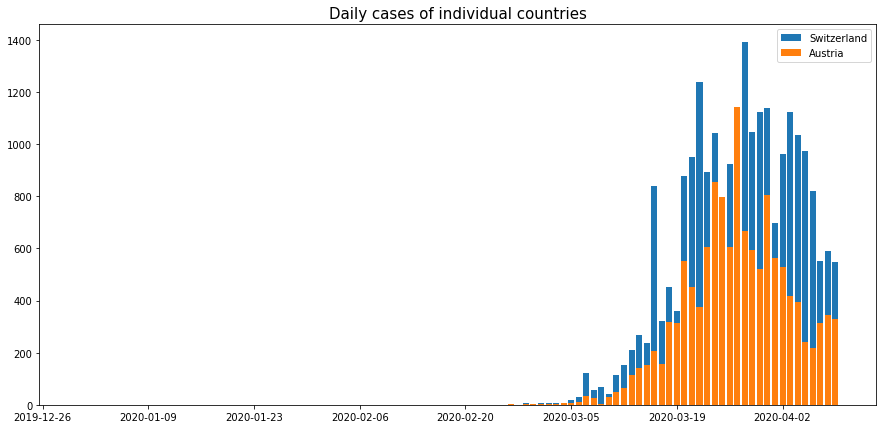

In [44]:
get_daily_cases(['Switzerland', 'Austria'])

In [50]:
def get_linechart(country = str):
    
    # getting the dataframe per country
    country_df = covid_dataset[covid_dataset['Countries and territories'] == country]
    
    # adding the column for cumulative cases
    cum_cases = country_df['Cases'][::-1]
    cum_cases = np.cumsum(cum_cases)
    cum_cases = cum_cases[::-1]
    country_df['CumulatedNewConfCases'] = cum_cases
    
    # adding the column for cumulative deaths
    cum_deaths = country_df['Deaths'][::-1]
    cum_deaths = np.cumsum(cum_deaths)
    cum_deaths = cum_deaths[::-1]
    country_df['CumulatedNewDeathCases'] = cum_deaths
    
    # line chart
    plt.rcParams['figure.figsize'] = (20,8)
    plt.bar(country_df['DateRep'], country_df['CumulatedNewConfCases'], label = 'Cases', lw = 2, color = 'pink')
    plt.bar(country_df['DateRep'], country_df['CumulatedNewDeathCases'], label = 'Deaths', lw = 2, color = 'purple')
    plt.title('Culumated cases and deaths {}: Cases = {} ; Deaths = {}'.format(country, \
                                country_df['CumulatedNewConfCases'].iloc[0], \
                                                            country_df['CumulatedNewDeathCases'].iloc[0]), fontsize = 15)
    plt.legend()
    plt.show()

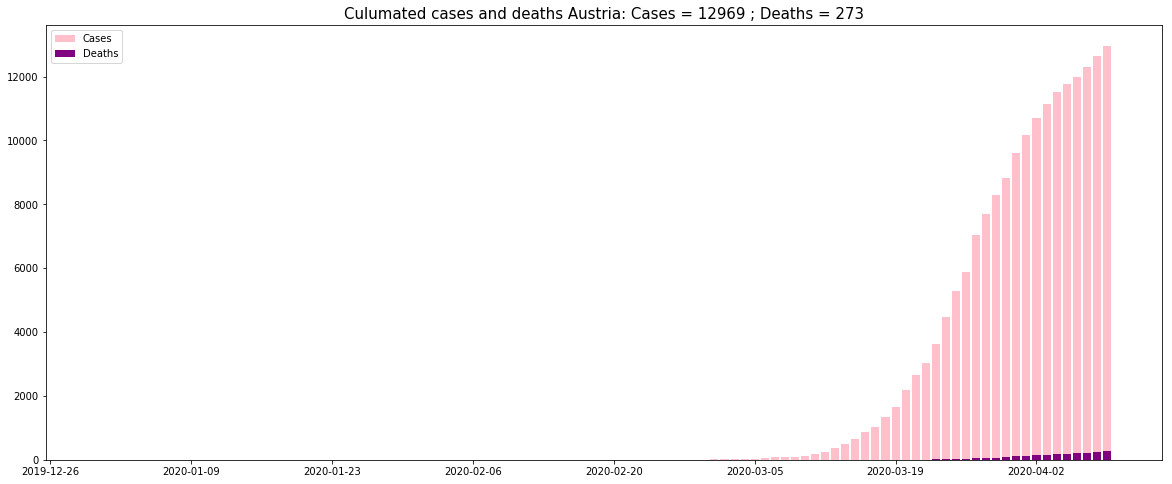

In [73]:
get_linechart('Austria')

### 2.2 Corona Process Comparison of individual Countries

In [52]:
def get_comp_infection_linechart(countries = []):
    
    # initializing subplots
    fig, ax = plt.subplots()
    
    # getting dataframe per country, add column of cumulated infections and plot it
    for country in countries:
        country_df = covid_dataset[covid_dataset['Countries and territories'] == country]
        cum_cases = country_df['Cases'][::-1]
        cum_cases = np.cumsum(cum_cases)
        cum_cases = cum_cases[::-1]
        country_df['CumulatedNewConfCases'] = cum_cases
        ax.plot(country_df['DateRep'], country_df['CumulatedNewConfCases'], label = country, lw = 2)
    plt.title('Comparison of infections of individual Countries', fontsize = 15)
    plt.legend()
    plt.show()

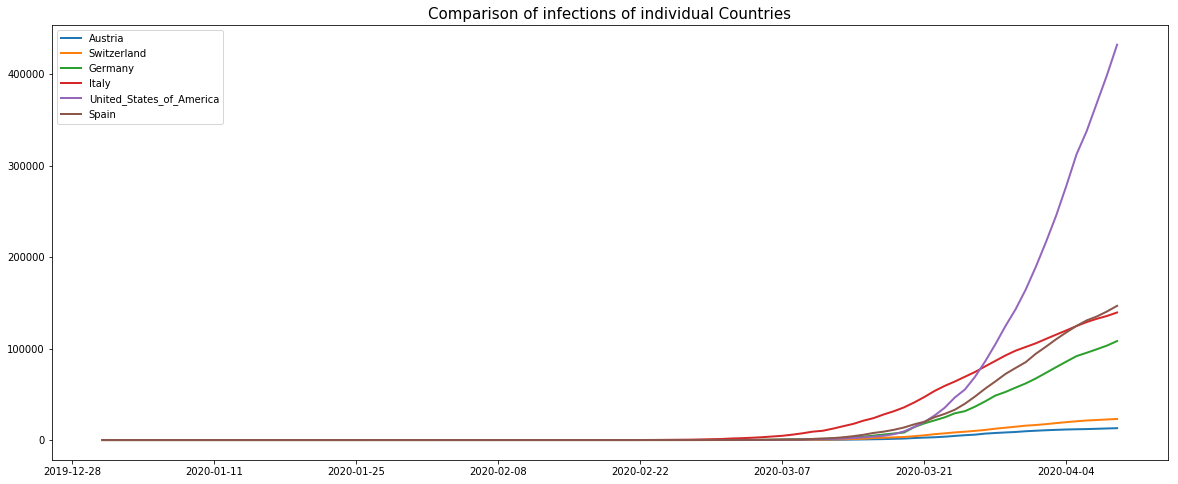

In [53]:
get_comp_infection_linechart(['Austria', 'Switzerland', 'Germany', 'Italy', 'United_States_of_America', 'Spain'])

In [54]:
def get_comp_death_linechart(countries = []):
    
    # initializing subplots
    fig, ax = plt.subplots()
    
    # getting dataframe per country, add column of cumulated infections and plot it
    for country in countries:
        country_df = covid_dataset[covid_dataset['Countries and territories'] == country]
        cum_deaths = country_df['Deaths'][::-1]
        cum_deaths = np.cumsum(cum_deaths)
        cum_deaths = cum_deaths[::-1]
        country_df['CumulatedNewDeathCases'] = cum_deaths
        ax.plot(country_df['DateRep'], country_df['CumulatedNewDeathCases'], label = country, lw = 2)
    plt.title('Comparison of deaths of individual Countries', fontsize = 15)
    plt.legend()
    plt.show()

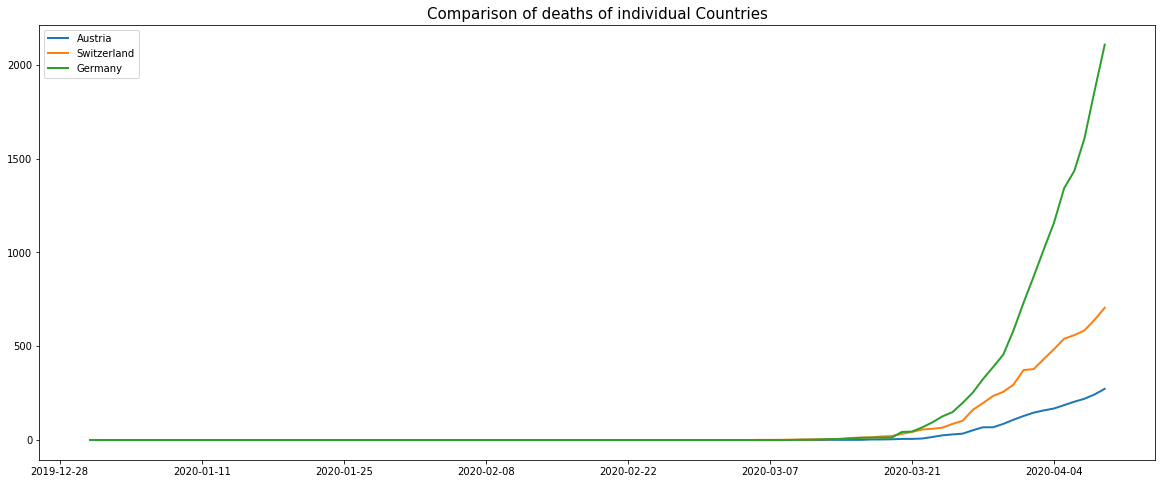

In [55]:
get_comp_death_linechart(['Austria', 'Switzerland', 'Germany'])

In [61]:
def get_comparison_XY_vs_CHINA(country = str, similarity = int):
    country_xy = covid_dataset[covid_dataset['Countries and territories'] == country]
    china = covid_dataset[covid_dataset['Countries and territories'] == 'China']
    
    # adding the column for cumulative cases austria
    cum_cases = country_xy['Cases'][::-1]
    cum_cases = np.cumsum(cum_cases)
    cum_cases = cum_cases[::-1]
    country_xy['CumulatedNewConfCases'] = cum_cases
    
    # adding the column for cumulative cases china
    cum_cases = china['Cases'][::-1]
    cum_cases = np.cumsum(cum_cases)
    cum_cases = cum_cases[::-1]
    china['CumulatedNewConfCases'] = (cum_cases * similarity) # divided by a number to make similar curves
    
    # adding days instead of dates
    days = country_xy['DateRep'][::-1]
    days = days.map(lambda x: (x - datetime.datetime.strptime('2020-01-01', '%Y-%m-%d')).days)
    country_xy['Days'] = days
    
    # adding days instead of dates
    days = china['DateRep'][::-1]
    days = days.map(lambda x: (x - datetime.datetime.strptime('2020-01-01', '%Y-%m-%d')).days)
    china['Days'] = days
    
    adjusted_days_count = list(range(0,50))
    
    fig, ax = plt.subplots()
    ax.plot(adjusted_days_count, country_xy['CumulatedNewConfCases'][:50][::-1], marker = 's', color = 'r', label = country)
    ax.plot(china['Days'], china['CumulatedNewConfCases'], marker = 's', color = 'grey',\
            alpha = 0.7, label = 'China')
    plt.title('Comparison of (adjusted) China Infections Curve with {}'.format(country), fontsize = 15)
    plt.legend()
    plt.show() 

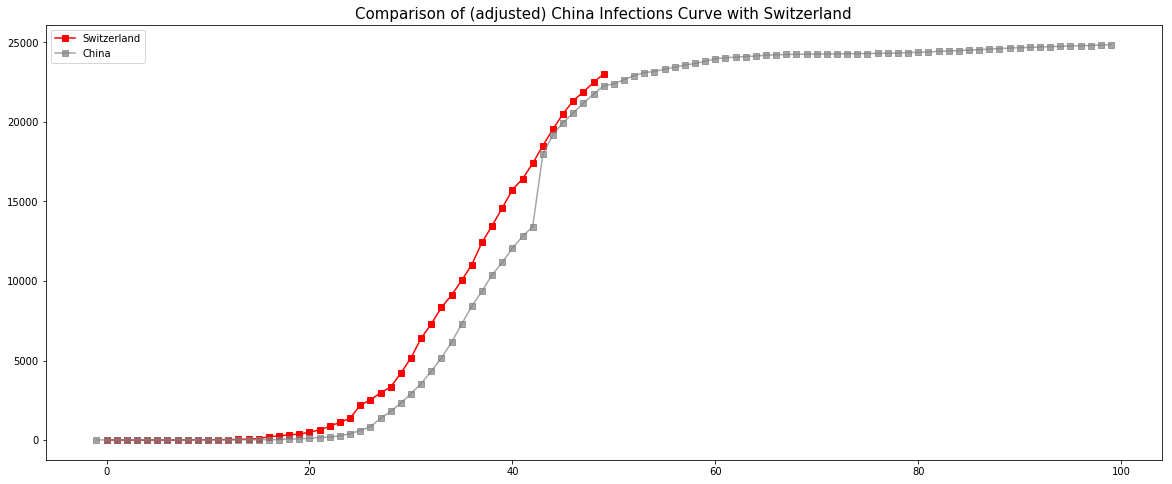

In [66]:
get_comparison_XY_vs_CHINA('Switzerland', 0.3)   

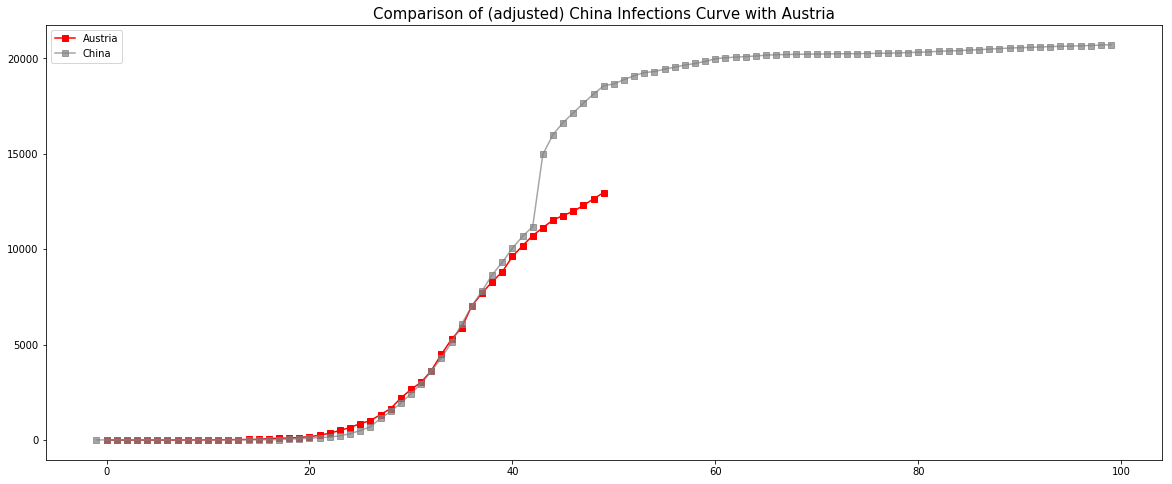

In [68]:
get_comparison_XY_vs_CHINA('Austria', 0.25)   

# ---------------------------------------------------------------------------------------------------------------

## 3. Predict Magnitude, Speed and Time of the Virus of specific Countries

In [2]:
# define logistic model
def logistic_model(x,a,b,c):
    return c/(1 + np.exp(-(x - b) / a))

In [1]:
def get_logistic_prediction(country = str, start_day = 0, initial_guess_p0 = []):
    
    # getting dataframe per country
    country_df = covid_dataset[covid_dataset['Countries and territories'] == country]
    
    # adding the column for cumulative cases
    cum_cases = country_df['Cases'][::-1]
    cum_cases = np.cumsum(cum_cases)
    cum_cases = cum_cases[::-1]
    country_df['CumulatedNewConfCases'] = cum_cases
    
    # transform dates to number of days == int
    days = country_df['DateRep'][::-1]
    days = days.map(lambda x: (x - datetime.datetime.strptime('2020-01-01', '%Y-%m-%d')).days)
    country_df['Days'] = days
    
    # define variables
    x = list(country_df.iloc[:,11])
    x = x[::-1]
    x = x[start_day:]            # in case you want to narrow the timespan!
    y = list(country_df.iloc[:,10])
    y = y[::-1]
    y = y[start_day:]
    
    # fitting the curve with scipy
    fit = curve_fit(logistic_model, x, y, p0 = initial_guess_p0, maxfev = 50000)
    fit
    
    # getting the results
    a = fit[0][0]
    b = fit[0][1]
    c = fit[0][2]
    
    # calculating errors
    errors = [np.sqrt(fit[1][i][i]) for i in [0,1,2]]
    
    # calculating the end date of the virus (i.e. the curve)
    sol = int(fsolve(lambda x : logistic_model(x,a,b,c) - int(c),b))
    
    # plot the results
    plt.rcParams['figure.figsize'] = (15,10)
    pred_x = list(range(max(x) + 1, sol))
    plt.scatter(x, y, label = 'Real data', color = 'red')
    plt.plot(x + pred_x, [logistic_model(i, a, b, c) for i in x + pred_x], label = 'Logistic model', color = 'blue')
    plt.legend()
    plt.title('Predicted Progress of the Corona Virus in {}'.format(country), fontsize = 15)
    plt.show()
    print('Infection Speed: ' + str(a) + '; (Error: ' + str(errors[0]) + ')')
    print('Days of Wave 1: ' + str(b) + '; (Error: ' + str(errors[1]) + ')')
    print('Number of Infections: ' + str(c) + '; (Error: ' + str(errors[2]) + ')')

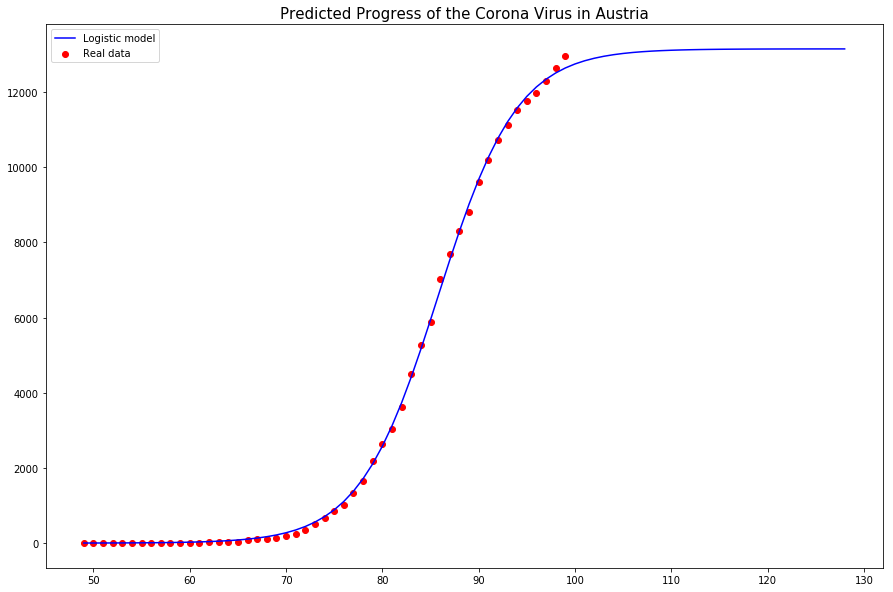

Infection Speed: 4.106438337968422; (Error: 0.05076514761348554)
Days of the Pandemie: 85.79605562638095; (Error: 0.07252601746773578)
Number of Infections: 13145.332458448009; (Error: 70.47340827300624)


In [76]:
get_logistic_prediction(country = 'Austria', start_day = 50, initial_guess_p0 = [2,100,20000])

# If results are strange, you have to play with initial_guess

# ---------------------------------------------------------------------------------------------------------------

## 4. Classification Models

### Get Dataset with more than a specific number of Infections

In [77]:
# get countries with more than 1000 (or more) infections

def get_df_with_specific_nr_of_cases(num_of_cases = int):
    countries = [i for i in covid_dataset['Countries and territories']]
    countries = np.unique(countries)
    global counrties_1000ormore_infections_list
    counrties_1000ormore_infections_list = []

    for country in countries:
        country_df = covid_dataset[covid_dataset['Countries and territories'] == country]
        if country_df['Cases'].sum() > num_of_cases:
            counrties_1000ormore_infections_list.append(country)
        else:
            pass
    counrties_1000ormore_infections_list.remove('China')
    countries_infection_df = \
        covid_dataset[covid_dataset['Countries and territories'].isin(counrties_1000ormore_infections_list)]
    return countries_infection_df

In [88]:
counrties_1000ormore_infections_df = get_df_with_specific_nr_of_cases(num_of_cases = 10000)
print(len(counrties_1000ormore_infections_list))

16


### Plot included Countries

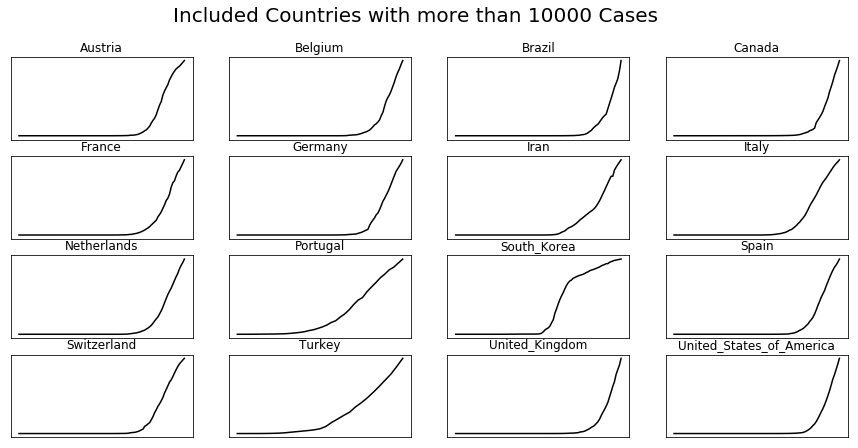

In [91]:
num_of_cases = 10000
rows = 4
columns = 4
counter = 0

fig, ax = plt.subplots(rows, columns, figsize = (15,7))


for row in range(0, rows):
    for column in range(0, columns):
        country_df = \
        counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == \
                                           counrties_1000ormore_infections_list[counter]]
        # adding the column for cumulative cases
        cum_cases = country_df['Cases'][::-1]
        cum_cases = np.cumsum(cum_cases)
        cum_cases = cum_cases[::-1]
        country_df['CumulatedNewConfCases'] = cum_cases
        
        ax[row, column].plot(country_df['DateRep'], country_df['CumulatedNewConfCases'], color = 'black')
        ax[row, column].set_xticks([])
        ax[row, column].set_yticks([])
        ax[row, column].set_title('{}'.format(counrties_1000ormore_infections_list[counter]))
        counter = counter + 1
fig.suptitle('Included Countries with more than {} Cases'.format(num_of_cases), fontsize = 20)
plt.show()

### Plot included Countries Cases History

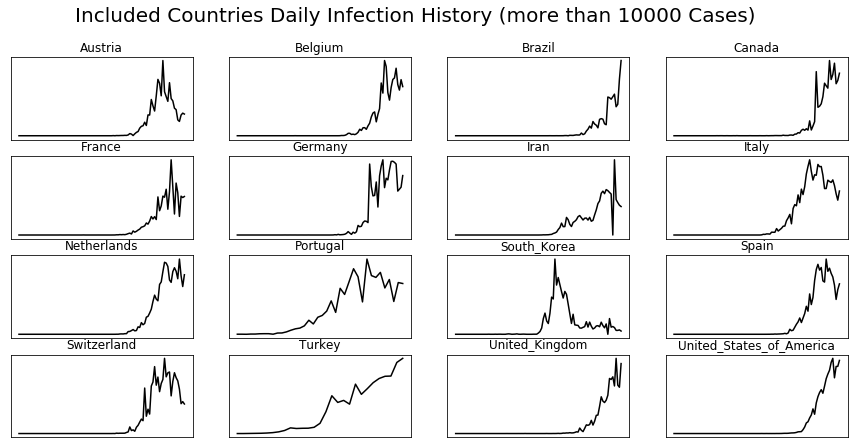

In [93]:
num_of_cases = 10000
rows = 4
columns = 4
counter = 0

fig, ax = plt.subplots(rows, columns, figsize = (15,7))


for row in range(0, rows):
    for column in range(0, columns):
        country_df = \
        counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == \
                                           counrties_1000ormore_infections_list[counter]]
        
        ax[row, column].plot(country_df['DateRep'], country_df['Cases'], color = 'black')
        ax[row, column].set_xticks([])
        ax[row, column].set_yticks([])
        ax[row, column].set_title('{}'.format(counrties_1000ormore_infections_list[counter]))
        counter = counter + 1
fig.suptitle('Included Countries Daily Infection History (more than {} Cases)'.format(num_of_cases), fontsize = 20)
plt.show()

### 4.1 TimeSeriesKMeans (China not included) with daily Infection Cases

[0 0 0 0 2 2 2 2 0 0 0 2 0 0 2 1]


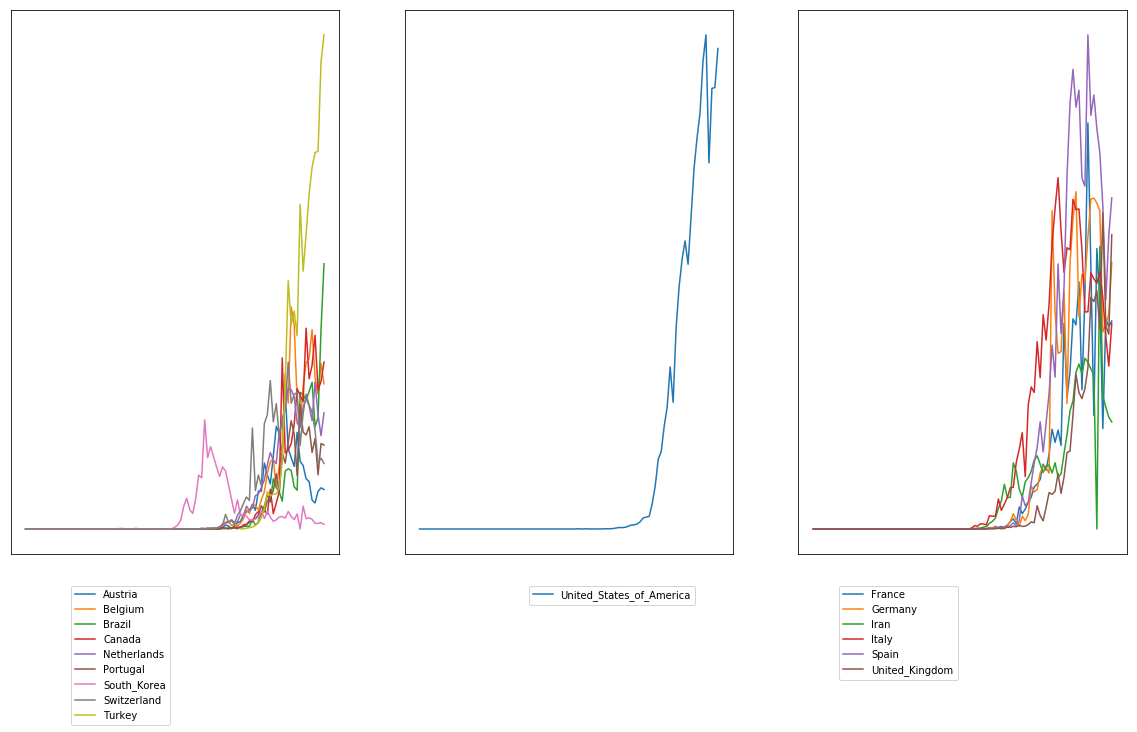

In [98]:
# transform data to matrix
cases_list = []

for country in counrties_1000ormore_infections_list:
    if country == 'CANADA':
        pass
    else:
        country_df = \
            counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == country]
        cases = list(country_df['Cases'].values)[::-1][-27:]
        for case in cases:
            cases_list.append(case)

cases_matrix = np.array(cases_list).reshape(16,27,1)

# perform times series kmeans
X = cases_matrix

ts_kmeans = TimeSeriesKMeans(n_clusters = 3, metric = "dtw", max_iter = 5, random_state = 2).fit(cases_matrix)
X_predict = ts_kmeans.predict(X)
print(X_predict)

# plot
fig, ax = plt.subplots(1,3, figsize = (20,10))

for i in range(0, len(counrties_1000ormore_infections_list)):
    if counrties_1000ormore_infections_list[i] == 'CANADA':
        pass
    else:
        country_df = \
            counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == \
                                              counrties_1000ormore_infections_list[i]]
        ax[X_predict[i]].plot(country_df['DateRep'], country_df['Cases'], label = counrties_1000ormore_infections_list[i])
ax[0].legend(bbox_to_anchor = (0.5, - 0.05))
ax[1].legend(bbox_to_anchor = (0.9, - 0.05))
ax[2].legend(bbox_to_anchor = (0.5, - 0.05))
ax[0].set_xticks([])
ax[1].set_xticks([])
ax[2].set_xticks([])
ax[0].set_yticks([])
ax[1].set_yticks([])
ax[2].set_yticks([])
plt.show()

### 4.2 Combination MDS - KMeans (China not included) with daily infection cases

#### 4.2.1 Combination Multi-Dimensional-Scaling (MDS) with K-Means WITH Data Scaling

[0 0 0 0 2 2 2 2 0 0 0 2 0 2 2 1]


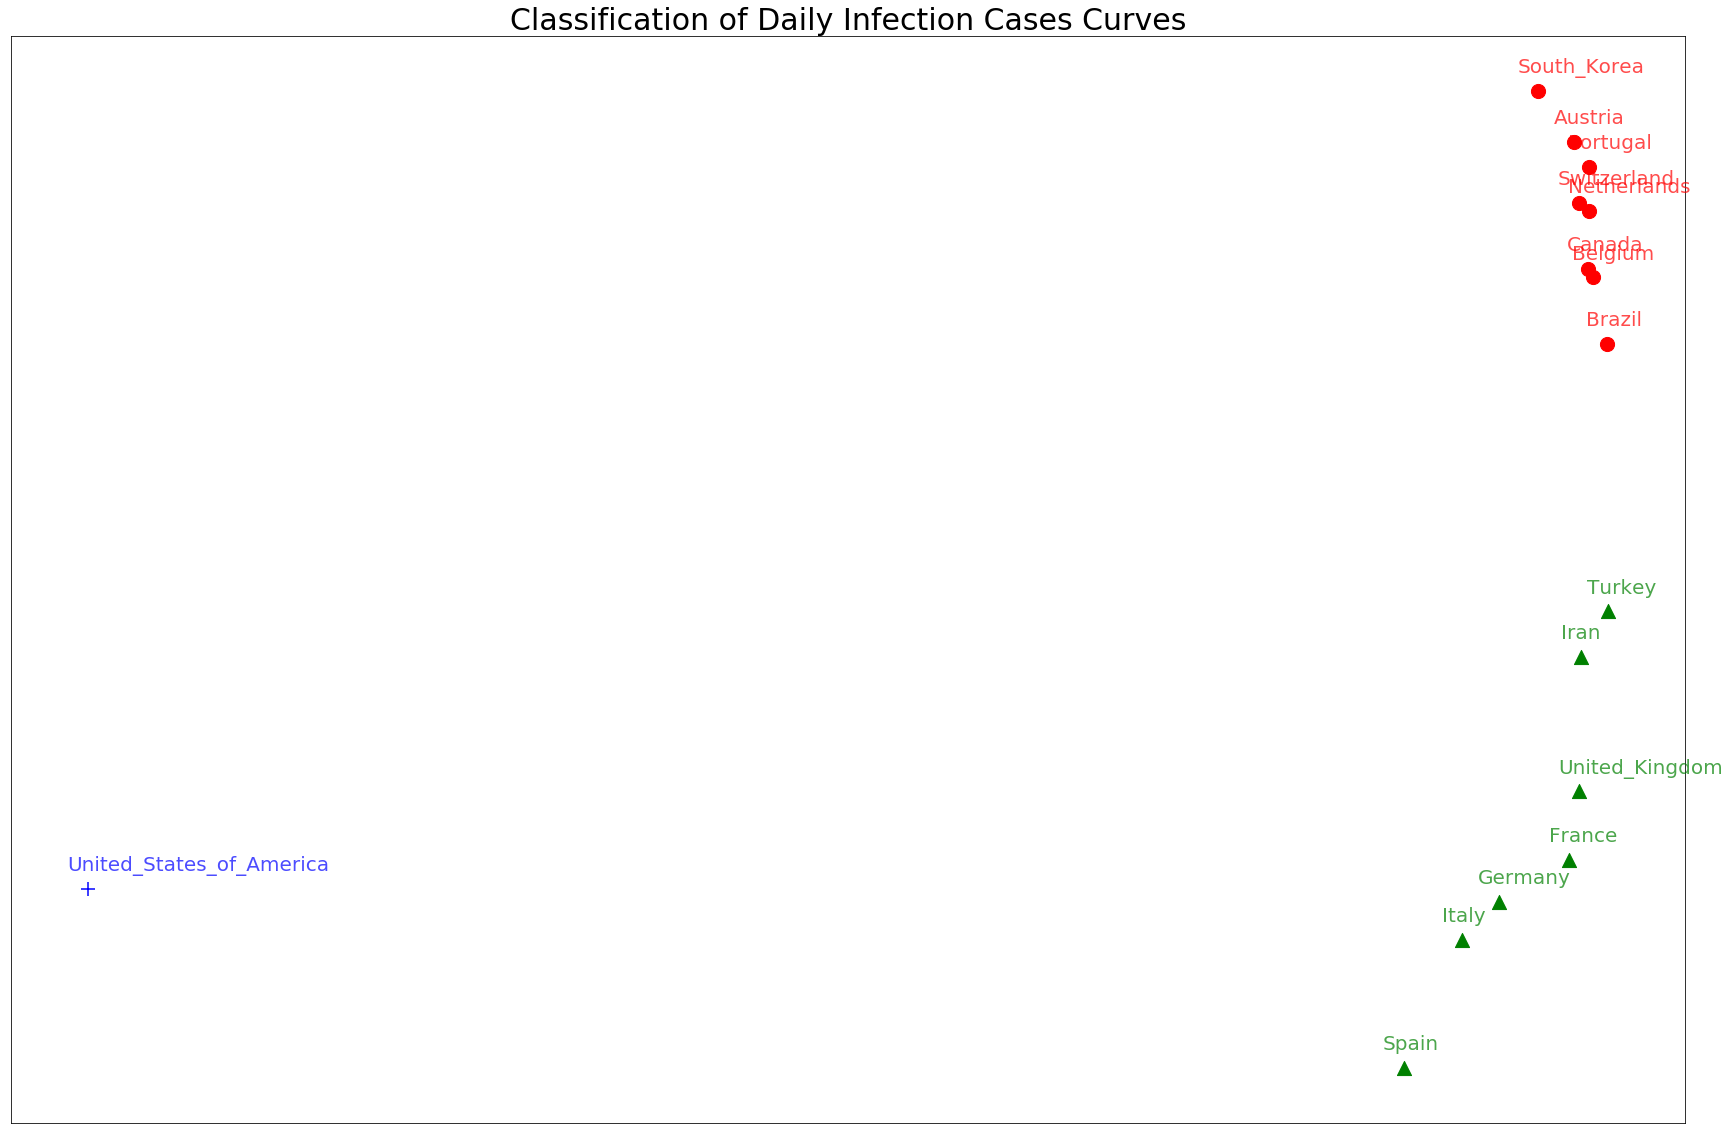

In [144]:
# distance matrix
distance_matrix = metrics.cdist_dtw(cases_matrix)

# scaling
scaler = MinMaxScaler()
scaler.fit(distance_matrix)
scaler_dist_matrix = scaler.transform(distance_matrix)

# multidimensional scaling
mds = MDS(n_components = 2)
X_transformed = mds.fit_transform(scaler_dist_matrix)

# kmeans
k_means = KMeans(n_clusters = 3, max_iter = 1000, random_state = 5)
predict = k_means.fit_predict(scaler_dist_matrix)
print(predict)

# plot
colors = {0: 'red', 1: 'blue', 2: 'green'}
markers = {0: 'o', 1: '+', 2: '^'}

plt.rcParams['figure.figsize'] = (30,20)
fig, ax = plt.subplots()

for i in range(0, len(X_transformed)):
    ax.scatter(X_transformed[i][0], X_transformed[i][1], color = colors[predict[i]], marker = markers[predict[i]], s = 200)
    ax.text(X_transformed[i][0] - 0.05, X_transformed[i][1] + 0.015, s = '{}'.format(counrties_1000ormore_infections_list[i]), \
            fontsize = 20, color = colors[predict[i]], alpha = 0.7)
plt.xticks([])
plt.yticks([])
plt.title('Classification of Daily Infection Cases Curves', fontsize = 30)
plt.show()

#### 4.2.2 Combination Multi-Dimensional-Scaling (MDS) with K-Means WITHOUT Data Scaling

[0 0 0 0 2 2 2 2 0 0 0 2 0 2 2 1]


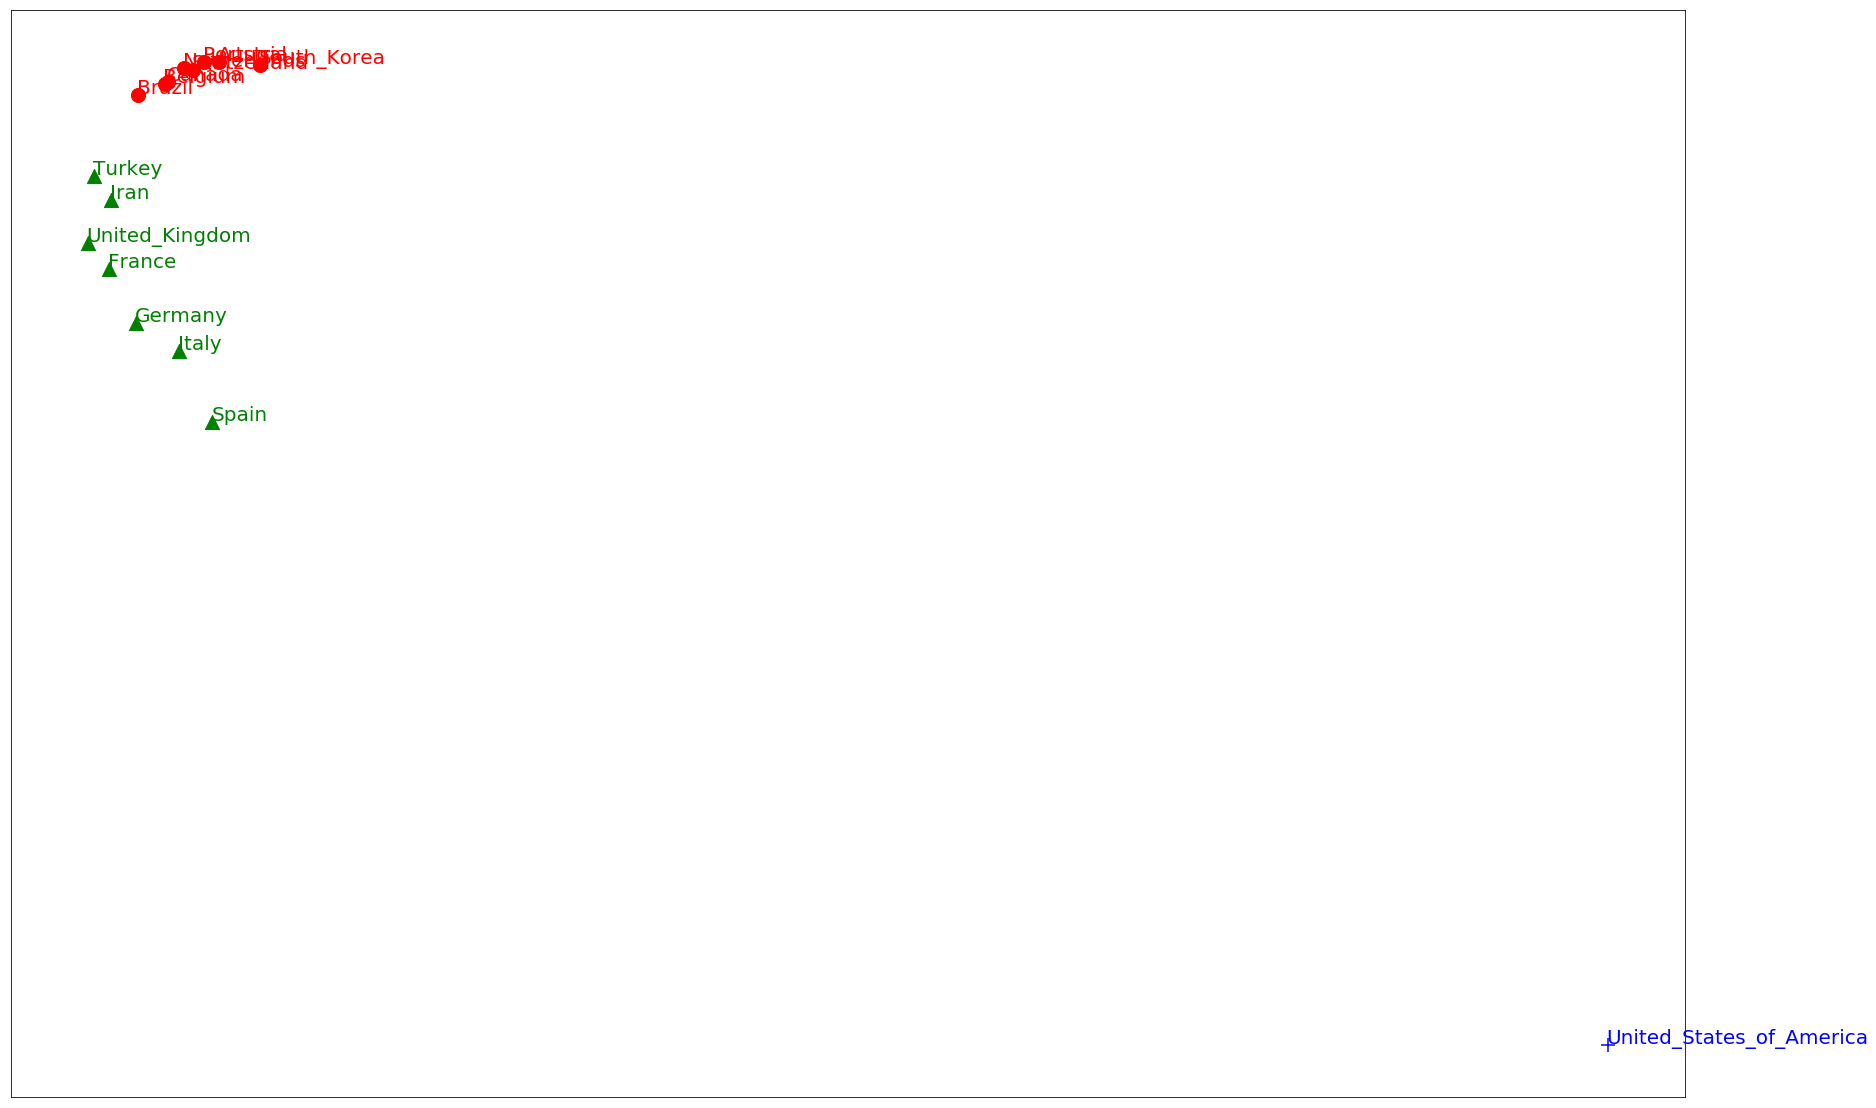

In [154]:
# distance matrix
distance_matrix = metrics.cdist_dtw(cases_matrix)

# multidimensional scaling
mds = MDS(n_components = 2)
X_transformed = mds.fit_transform(distance_matrix)

# kmeans
k_means = KMeans(n_clusters = 3, max_iter = 1000, random_state = 3)
predict = k_means.fit_predict(distance_matrix)
print(predict)

# plot
colors = {0: 'red', 1: 'blue', 2: 'green'}
markers = {0: 'o', 1: '+', 2: '^'}

plt.rcParams['figure.figsize'] = (30,20)
fig, ax = plt.subplots()

for i in range(0, len(X_transformed)):
    ax.scatter(X_transformed[i][0], X_transformed[i][1], color = colors[predict[i]], marker = markers[predict[i]], s = 200)
    ax.text(X_transformed[i][0] - 200, X_transformed[i][1] + 350, s = '{}'.format(counrties_1000ormore_infections_list[i]), \
            fontsize = 20, color = colors[predict[i]])
plt.xticks([])
plt.yticks([])
plt.show()

## 5. Adding more Variables for different Analysis

In [155]:
# adding cumulative infection cases and cumulative death cases
cum_cases_total = []
cum_deaths_total = []

for country in counrties_1000ormore_infections_list:
    # getting the dataframe per country
    country_df = covid_dataset[covid_dataset['Countries and territories'] == country]
    
    # adding the column for cumulative cases
    cum_cases = country_df['Cases'][::-1]
    cum_cases = np.cumsum(cum_cases)
    cum_cases = cum_cases[::-1]
    for case in cum_cases:
        cum_cases_total.append(case)
    
    # adding the column for cumulative deaths
    cum_deaths = country_df['Deaths'][::-1]
    cum_deaths = np.cumsum(cum_deaths)
    cum_deaths = cum_deaths[::-1]
    for death in cum_deaths:
        cum_deaths_total.append(death)
    
counrties_1000ormore_infections_df['CumulatedNewConfCases'] = cum_cases_total
counrties_1000ormore_infections_df['CumulatedNewDeathCases'] = cum_deaths_total

# adding percentual growth per day
perc_growth_total = []

for country in counrties_1000ormore_infections_list:
    perc_growth = []
    
    # getting the dataframe per country
    country_df = counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == country]
    
    perc_cum_cases = [i for i in country_df['CumulatedNewConfCases']][::-1]
    compared_values = list(zip(perc_cum_cases, perc_cum_cases[1:]))
    for perc in compared_values:
        if perc[0] == 0:
            perc_growth.append(0)
        else:
            growth = (perc[1] / perc[0]) -1
            perc_growth.append(growth)

    first_value = 0
    perc_growth.insert(0, first_value)
    perc_growth = perc_growth[::-1]

    for i in perc_growth:
        perc_growth_total.append(i)
        
counrties_1000ormore_infections_df['PercGrowth'] = perc_growth_total

# adding doubling rate
doubling_rate = counrties_1000ormore_infections_df['PercGrowth']
doubling_rate = doubling_rate.map(lambda x: round(1 / x, 2) if x != 0 else 0)
counrties_1000ormore_infections_df['DoublingRate'] = doubling_rate
counrties_1000ormore_infections_df.head()

,DateRep,day,month,year,Cases,Deaths,Countries and territories,geoId,countryterritoryCode,popData2018,CumulatedNewConfCases,CumulatedNewDeathCases,PercGrowth,DoublingRate
545,2020-04-09,9,4,2020,329,30,Austria,AT,AUT,8847037.0,12969,273,0.026028,38.42
546,2020-04-08,8,4,2020,343,23,Austria,AT,AUT,8847037.0,12640,243,0.027893,35.85
547,2020-04-07,7,4,2020,314,16,Austria,AT,AUT,8847037.0,12297,220,0.026204,38.16
548,2020-04-06,6,4,2020,217,18,Austria,AT,AUT,8847037.0,11983,204,0.018443,54.22
549,2020-04-05,5,4,2020,241,18,Austria,AT,AUT,8847037.0,11766,186,0.020911,47.82


### 5.1 Doubling Rates Line Chart of individual Countries

In [193]:
def get_doubling_rates_linechart(countries = []):
    
    # initializing subplots
    fig, ax = plt.subplots(figsize = (15,10))
    
    # getting dataframe per country and plot it
    for country in countries:
        country_df = counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories']\
                                                        == country]
        ax.plot(country_df['DateRep'], country_df['DoublingRate'], label = country, lw = 2)
    plt.title('Comparison of doubling rates of individual Countries', fontsize = 15)
    plt.legend(loc = 'upper left')
    plt.show()

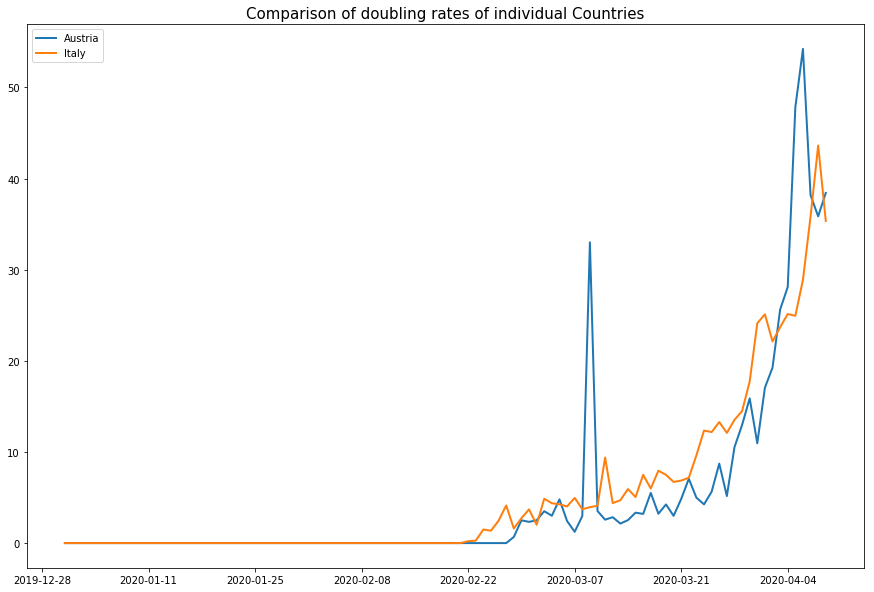

In [199]:
get_doubling_rates_linechart(['Austria', 'Italy'])

### 5.2 Percentual Growth Line Chart for individual Countries

In [200]:
def get_percentual_growth_linechart(countries = []):
    
    # initializing subplots
    fig, ax = plt.subplots(figsize = (15,10))
    
    # getting dataframe per country and plot it
    for country in countries:
        country_df = counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == country]
        ax.plot(country_df['DateRep'], country_df['PercGrowth'], label = country, lw = 2)
    plt.title('Comparison of percentual growth of individual Countries', fontsize = 15)
    plt.legend()
    plt.show()

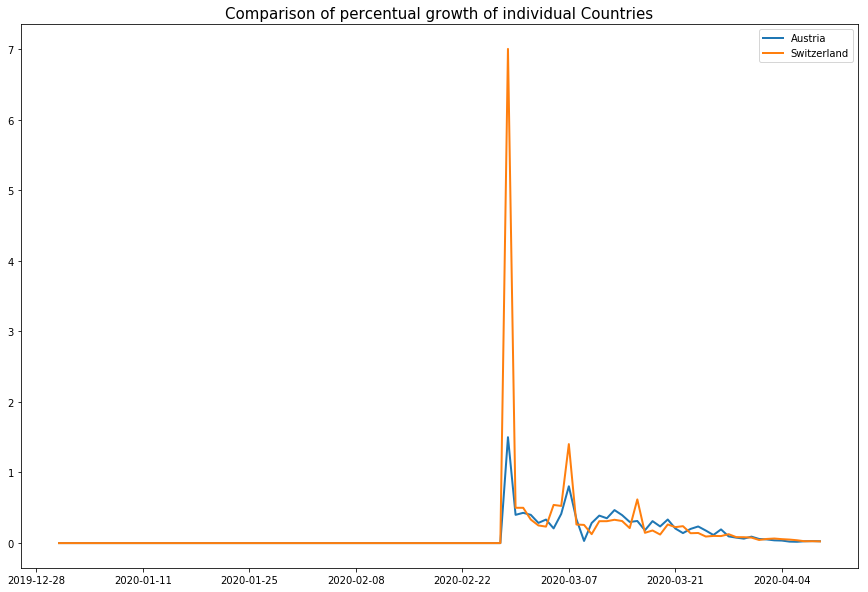

In [201]:
get_percentual_growth_linechart(['Austria', 'Switzerland'])

## 6. Adding new Datasets for further detailed Analysis

In [202]:
# import population dataset and adjust some names
population = pd.read_csv(r'C:\Users\Bernhard Brugger\Desktop\CoVid_19\population_2020.csv')
population = population.replace('United States', 'United_States_of_America').replace('South Korea', 'South_Korea').replace('United Kingdom', 'United_Kingdom').replace('Czech Republic', 'Czech_Republic')

In [203]:
def get_current_population(country = str):
    country_pop = population[population['name'] == country]
    country_pop = country_pop['pop2020'].values[0] * 1000
    return country_pop

In [204]:
def get_covid_country_infections(country = str):
    adjusted_country_names = {'United States': 'United_States_of_America'}
    
    covid_subdataset = covid_dataset[covid_dataset['Countries and territories'] == country]
    return covid_subdataset['Cases'].sum()

In [205]:
# infection cases per 1000 people
#counrties_1000ormore_infections_adjusted_list = [word.replace('_', ' ').replace(' of America', '') \
#                                                for word in counrties_1000ormore_infections_list]
countries = [i for i in covid_dataset['Countries and territories']]
countries = np.unique(countries)
country_name = []
infection_per_1000_people = []

for country in countries:
    try:
        perc = (get_covid_country_infections(country) / get_current_population(country)) * 1000
        country_name.append(country)
        infection_per_1000_people.append(perc)
    except IndexError:
        country_name.append(country)
        infection_per_1000_people.append('No Information')
infection_per_1000_people_dict = dict(zip(country_name, infection_per_1000_people))
infection_per_1000_people_df = pd.DataFrame(list(infection_per_1000_people_dict.items()), \
                                           columns = ['Country', 'InfPer1000Peop'])
infection_per_1000_people_df = infection_per_1000_people_df.replace('No Information', 0)
infection_per_1000_people_df = infection_per_1000_people_df.sort_values( by = 'InfPer1000Peop', ascending = False)

# add column population density and country size
population = population.drop(['rank', 'densityMi', 'pop2020'], axis = 1)
population = population.rename(columns = {'name': 'Country'})
merged_df = infection_per_1000_people_df.merge(population, on = 'Country')
merged_df = merged_df.rename(columns = {'density': 'density/km2', 'area': 'area(km2)'})

# get only those countries with more than 1000 infections
merged_df = merged_df[merged_df['Country'].isin(counrties_1000ormore_infections_list)].reset_index(drop = True)
merged_df

,Country,InfPer1000Peop,density/km2,area(km2)
0,Spain,3.137433,92.4022,505992.0
1,Switzerland,2.661006,209.6362,41284.0
2,Italy,2.305951,200.6459,301336.0
3,Belgium,2.019306,379.6391,30528.0
4,Austria,1.439976,107.3839,83871.0
5,United_States_of_America,1.305524,35.3160,9372610.0
6,Germany,1.291441,234.6140,357114.0
7,Portugal,1.288749,110.7255,92090.0
8,France,1.256988,118.3145,551695.0
9,Netherlands,1.199250,409.4354,41850.0


### 6.1 KMeans Infection Rate / 1000 People VERSUS Population-Density

[1 1 1 1 0 0 0 0 0 0 0 2 2 2 2 2]


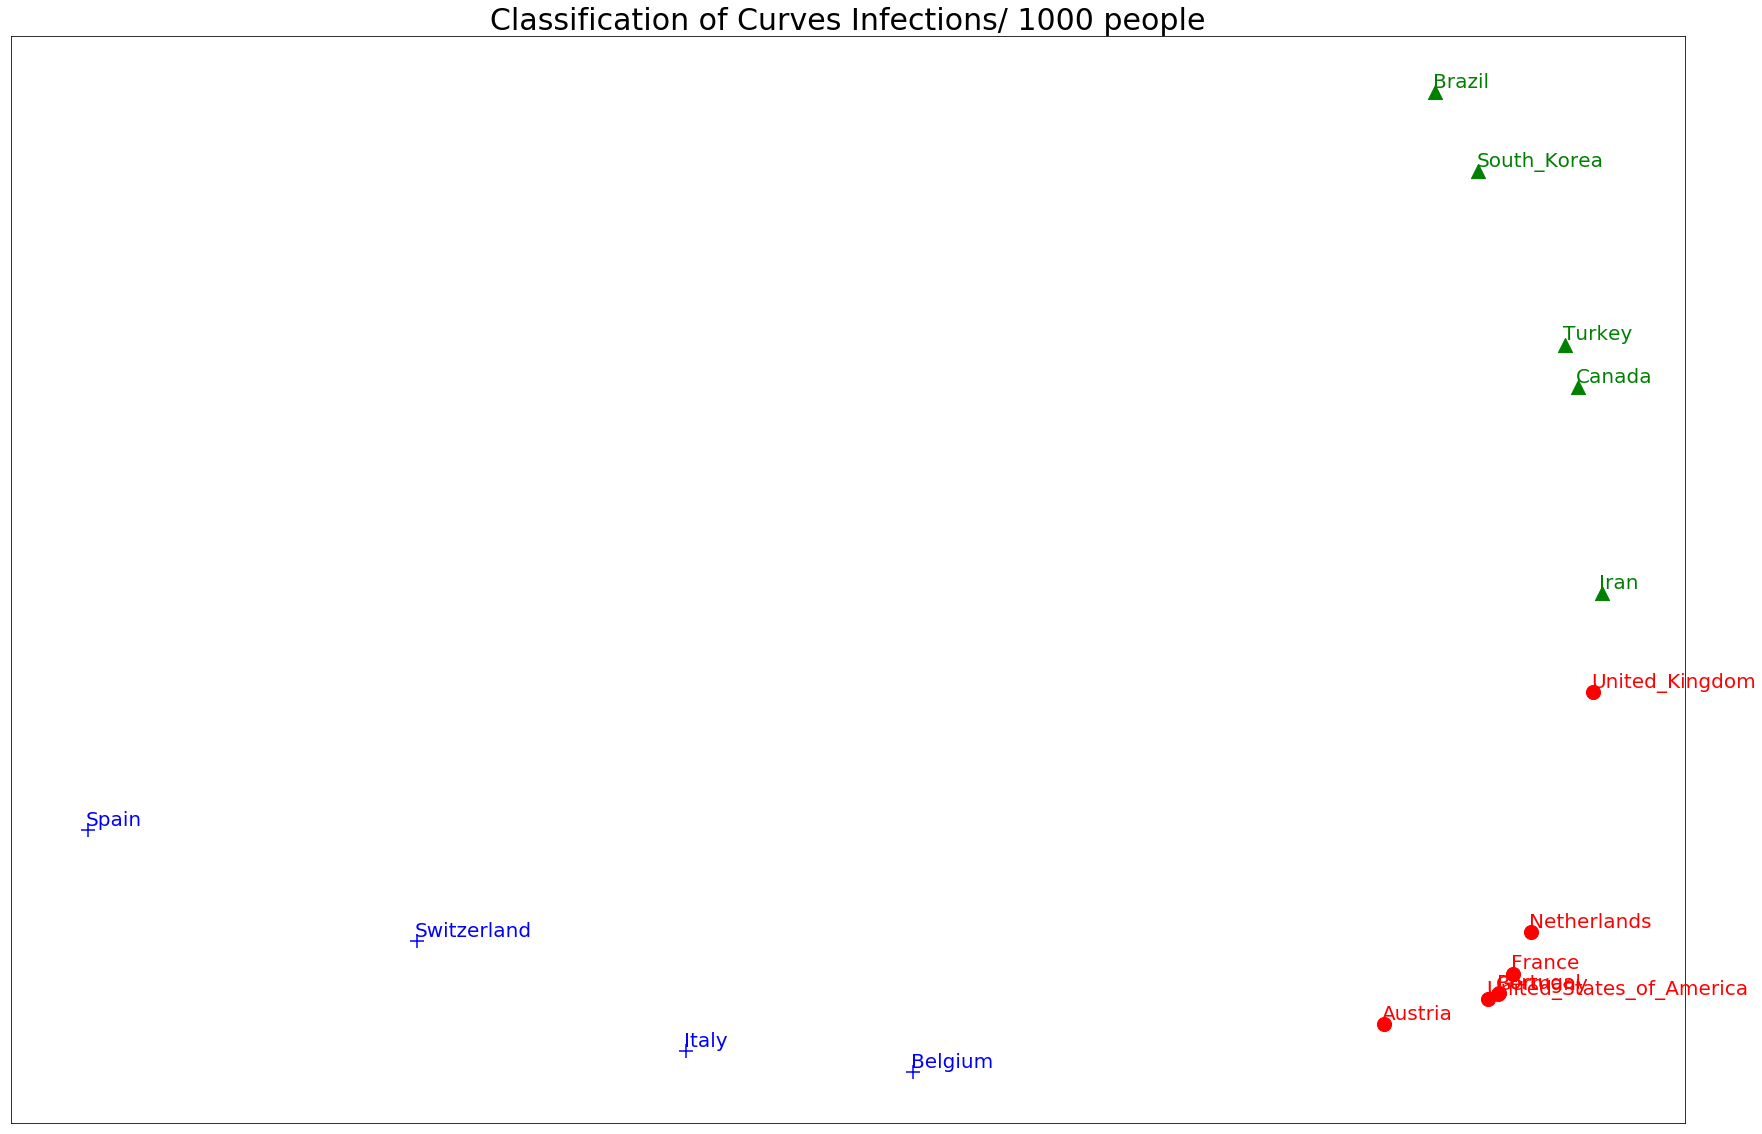

In [206]:
# create matrix
X = list(merged_df['InfPer1000Peop'])
X = np.array(X).reshape(len(merged_df),1,1)

# calculate distance matrix
distance_matrix = metrics.cdist_dtw(X)

# multidimensional scaling
mds = MDS(n_components = 2)
X_transformed = mds.fit_transform(distance_matrix)

# kmeans
k_means = KMeans(n_clusters = 3, max_iter = 1000, random_state = 1)
predict = k_means.fit_predict(distance_matrix)
print(predict)

# plot
colors = {0: 'red', 1: 'blue', 2: 'green'}
markers = {0: 'o', 1: '+', 2: '^'}

plt.rcParams['figure.figsize'] = (30,20)
fig, ax = plt.subplots()

for i in range(0, len(X_transformed)):
    ax.scatter(X_transformed[i][0], X_transformed[i][1], color = colors[predict[i]], marker = markers[predict[i]], s = 200)
    ax.text(X_transformed[i][0] - 0.01, X_transformed[i][1] + 0.02, s = '{}'.format(merged_df['Country'][i]), \
            fontsize = 20, color = colors[predict[i]])
plt.xticks([])
plt.yticks([])
plt.title('Classification of Curves Infections/ 1000 people', fontsize = 30)
plt.show()

In [971]:
#-----------------------------OPTIONAL: TimeSeriesKMeans für den prozentualen Anstieg-------------------------------------------

In [ ]:
cases_list = []

for country in counrties_1000ormore_infections_list:
    if country == 'CANADA':
        pass
    else:
        country_df = \
            counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == country]
        cases = list(country_df['PercGrowth'].values)[::-1][-19:]
        for case in cases:
            cases_list.append(case)

cases_matrix = np.array(cases_list).reshape(18,19,1)

In [925]:
X = cases_matrix

ts_kmeans = TimeSeriesKMeans(n_clusters = 3, metric = "dtw", max_iter = 5).fit(cases_matrix)
X_predict = ts_kmeans.predict(X)
X_predict

array([1, 0, 2, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1], dtype=int64)

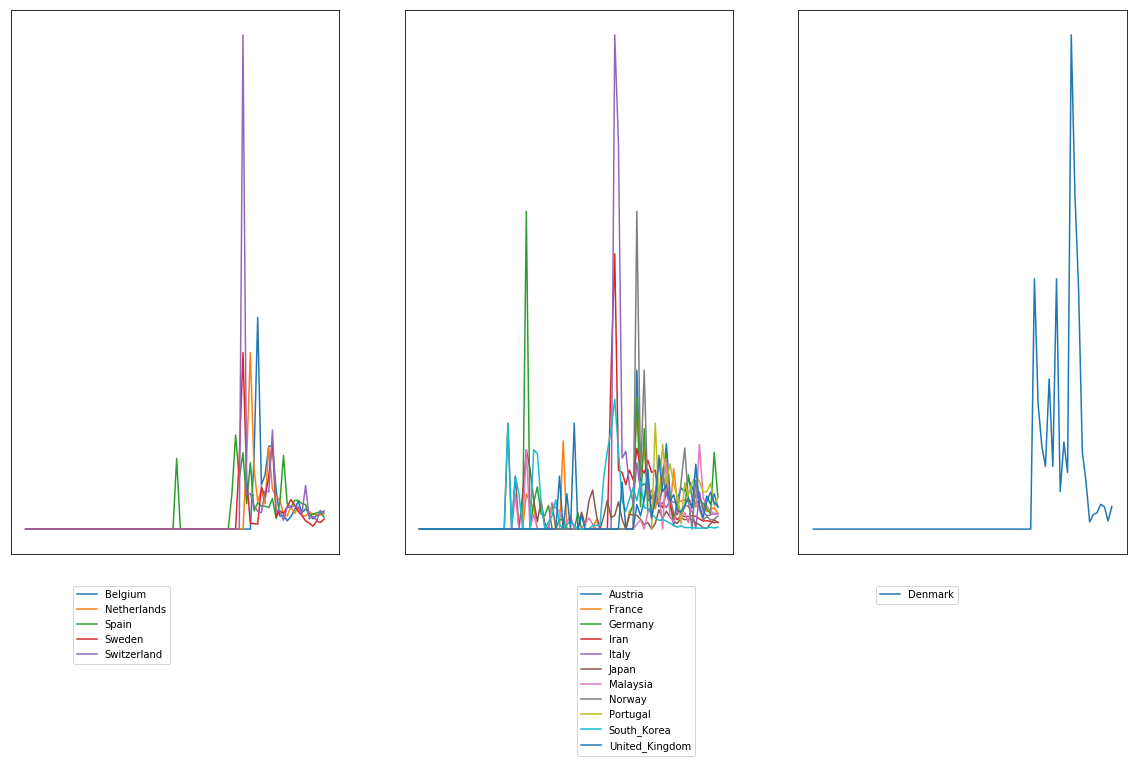

In [926]:
fig, ax = plt.subplots(1,3, figsize = (20,10))

for i in range(0, len(counrties_1000ormore_infections_list) - 1):
    if counrties_1000ormore_infections_list[i] == 'CANADA':
        pass
    else:
        country_df = \
            counrties_1000ormore_infections_df[counrties_1000ormore_infections_df['Countries and territories'] == \
                                              counrties_1000ormore_infections_list[i]]
        ax[X_predict[i]].plot(country_df['DateRep'], country_df['PercGrowth'], label = counrties_1000ormore_infections_list[i])
ax[0].legend(bbox_to_anchor = (0.5, - 0.05))
ax[1].legend(bbox_to_anchor = (0.9, - 0.05))
ax[2].legend(bbox_to_anchor = (0.5, - 0.05))
ax[0].set_xticks([])
ax[1].set_xticks([])
ax[2].set_xticks([])
ax[0].set_yticks([])
ax[1].set_yticks([])
ax[2].set_yticks([])
plt.show()
        